In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('telco_churn.csv')
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'telco_churn.csv'

In [3]:
import os
print(os.getcwd())
print([f for f in os.listdir() if 'csv' in f.lower() or 'telco' in f.lower() or 'churn' in f.lower()])

C:\Users\RPC
['Advertising.csv', 'Churn_Prediction.ipynb', 'student_data.csv', 'telco_churn.csv.csv']


In [4]:
df = pd.read_csv('telco_churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
print("Dimensions :", df.shape)
print()
df.info()

Dimensions : (7043, 21)

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-n

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


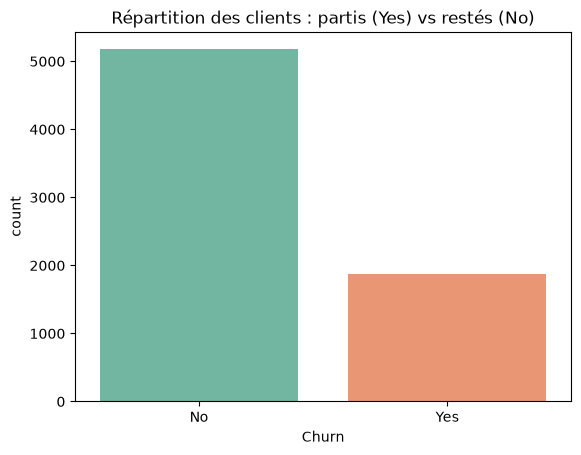

In [6]:
print(df['Churn'].value_counts())
print()
print(df['Churn'].value_counts(normalize=True).round(3) * 100)

sns.countplot(x='Churn', data=df, hue='Churn', palette='Set2', legend=False)
plt.title("Répartition des clients : partis (Yes) vs restés (No)")
plt.show()

In [7]:
# Convertir en nombre : les valeurs vides deviennent NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print("Valeurs manquantes par colonne :")
print(df.isnull().sum()[df.isnull().sum() > 0])

Valeurs manquantes par colonne :
TotalCharges    11
dtype: int64


In [8]:
# Qui sont ces clients ?
df[df['TotalCharges'].isnull()][['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [9]:
# Ce sont de nouveaux clients (tenure = 0) : leur total facturé est donc 0
df['TotalCharges'] = df['TotalCharges'].fillna(0)

print("Valeurs manquantes restantes :", df.isnull().sum().sum())

Valeurs manquantes restantes : 0


In [10]:
# customerID est un identifiant, il n'aide pas à prédire
df = df.drop('customerID', axis=1)

# Cible : Yes -> 1, No -> 0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

df['Churn'].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [11]:
X = df.drop('Churn', axis=1)
y = df['Churn']

# Chaque catégorie devient une colonne 0/1
X = pd.get_dummies(X, drop_first=True)

print("Nombre de colonnes avant :", df.shape[1] - 1)
print("Nombre de colonnes après :", X.shape[1])
X.head()

Nombre de colonnes avant : 19
Nombre de colonnes après : 30


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,True,False,False,True,False,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,True,False,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,False,False,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train :", X_train.shape)
print("Test  :", X_test.shape)
print("\nTaux de churn train :", round(y_train.mean() * 100, 1), "%")
print("Taux de churn test  :", round(y_test.mean() * 100, 1), "%")

Train : (5634, 30)
Test  : (1409, 30)

Taux de churn train : 26.5 %
Taux de churn test  : 26.5 %


In [13]:
from sklearn.preprocessing import StandardScaler

cols_num = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler = StandardScaler()
X_train[cols_num] = scaler.fit_transform(X_train[cols_num])  # apprend sur le train
X_test[cols_num] = scaler.transform(X_test[cols_num])        # applique au test

X_train[cols_num].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,5634.00,5634.00,5634.00
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-1.32,-1.54,-1.01
25%,-0.96,-0.97,-0.83
50%,-0.14,0.18,-0.40
75%,0.92,0.83,0.67
max,1.61,1.79,2.80


In [14]:
baseline = 1 - y_test.mean()
print(f"Baseline (prédire que personne ne part) : {baseline * 100:.1f}%")

Baseline (prédire que personne ne part) : 73.5%


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

modele_lr = LogisticRegression(max_iter=1000, random_state=42)
modele_lr.fit(X_train, y_train)

pred_lr = modele_lr.predict(X_test)
print(f"Régression logistique : {accuracy_score(y_test, pred_lr) * 100:.1f}%")

Régression logistique : 80.6%


In [16]:
from sklearn.tree import DecisionTreeClassifier

modele_dt = DecisionTreeClassifier(random_state=42)
modele_dt.fit(X_train, y_train)

print(f"Arbre de décision (test)  : {accuracy_score(y_test, modele_dt.predict(X_test)) * 100:.1f}%")
print(f"Arbre de décision (train) : {accuracy_score(y_train, modele_dt.predict(X_train)) * 100:.1f}%")

Arbre de décision (test)  : 72.5%
Arbre de décision (train) : 99.8%


In [17]:
from sklearn.tree import DecisionTreeClassifier

modele_dt = DecisionTreeClassifier(random_state=42)
modele_dt.fit(X_train, y_train)

print(f"Arbre de décision (test)  : {accuracy_score(y_test, modele_dt.predict(X_test)) * 100:.1f}%")
print(f"Arbre de décision (train) : {accuracy_score(y_train, modele_dt.predict(X_train)) * 100:.1f}%")

Arbre de décision (test)  : 72.5%
Arbre de décision (train) : 99.8%


In [18]:
from sklearn.ensemble import RandomForestClassifier

modele_rf = RandomForestClassifier(n_estimators=200, random_state=42)
modele_rf.fit(X_train, y_train)

print(f"Random Forest (test)  : {accuracy_score(y_test, modele_rf.predict(X_test)) * 100:.1f}%")
print(f"Random Forest (train) : {accuracy_score(y_train, modele_rf.predict(X_train)) * 100:.1f}%")

Random Forest (test)  : 79.0%
Random Forest (train) : 99.8%


In [19]:
resultats = pd.DataFrame({
    'Modèle': ['Baseline', 'Régression logistique', 'Arbre de décision', 'Random Forest'],
    'Accuracy test (%)': [
        baseline * 100,
        accuracy_score(y_test, pred_lr) * 100,
        accuracy_score(y_test, modele_dt.predict(X_test)) * 100,
        accuracy_score(y_test, modele_rf.predict(X_test)) * 100
    ]
}).round(1)

resultats

,Modèle,Accuracy test (%)
0,Baseline,73.5
1,Régression logistique,80.6
2,Arbre de décision,72.5
3,Random Forest,79.0


In [20]:
from sklearn.metrics import classification_report

print("=== Régression logistique ===")
print(classification_report(y_test, pred_lr, target_names=['Reste', 'Part']))

print("=== Random Forest ===")
print(classification_report(y_test, modele_rf.predict(X_test), target_names=['Reste', 'Part']))

=== Régression logistique ===
              precision    recall  f1-score   support

       Reste       0.85      0.90      0.87      1035
        Part       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

=== Random Forest ===
              precision    recall  f1-score   support

       Reste       0.83      0.89      0.86      1035
        Part       0.63      0.51      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



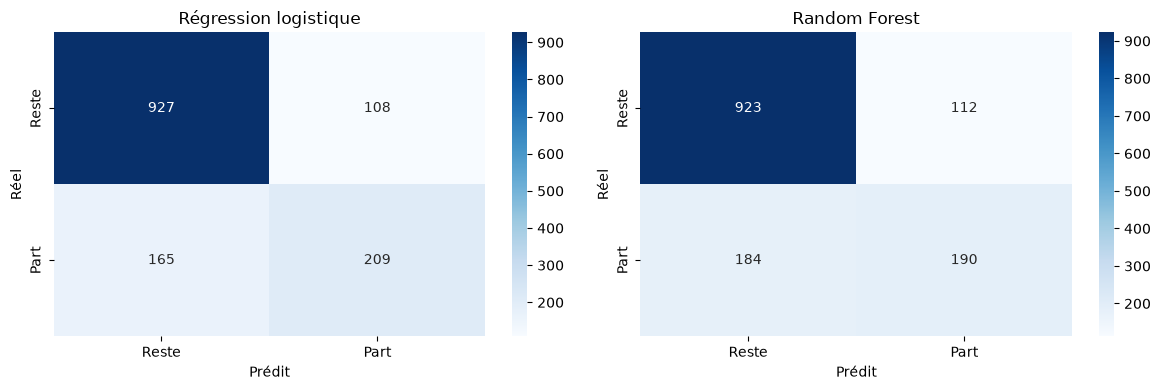

In [21]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (nom, pred) in zip(axes, [('Régression logistique', pred_lr),
                                   ('Random Forest', modele_rf.predict(X_test))]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Reste', 'Part'], yticklabels=['Reste', 'Part'])
    ax.set_title(nom)
    ax.set_xlabel('Prédit')
    ax.set_ylabel('Réel')

plt.tight_layout()
plt.show()

In [22]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(modele_lr, X_train, y_train, cv=5, scoring='recall')
print("Rappel sur 5 découpages :", scores.round(3))
print(f"Moyenne : {scores.mean():.3f}  (écart-type : {scores.std():.3f})")

Rappel sur 5 découpages : [0.599 0.522 0.542 0.538 0.542]
Moyenne : 0.548  (écart-type : 0.026)


In [23]:
from sklearn.metrics import precision_score, recall_score, f1_score

lr_bal = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr_bal.fit(X_train, y_train)
pred_bal = lr_bal.predict(X_test)

print("=== Régression logistique pondérée ===")
print(classification_report(y_test, pred_bal, target_names=['Reste', 'Part']))

=== Régression logistique pondérée ===
              precision    recall  f1-score   support

       Reste       0.90      0.72      0.80      1035
        Part       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [24]:
proba = modele_lr.predict_proba(X_test)[:, 1]   # probabilité de départ

lignes = []
for seuil in [0.5, 0.4, 0.3, 0.2]:
    pred = (proba >= seuil).astype(int)
    lignes.append({
        'Seuil': seuil,
        'Précision': precision_score(y_test, pred),
        'Rappel': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred)
    })

pd.DataFrame(lignes).round(3)

,Seuil,Précision,Rappel,F1
0,0.5,0.659,0.559,0.605
1,0.4,0.570,0.666,0.614
2,0.3,0.520,0.757,0.617
3,0.2,0.467,0.856,0.604


In [25]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'class_weight': [None, 'balanced']
}

grid = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    param_grid, cv=5, scoring='f1'
)
grid.fit(X_train, y_train)

print("Meilleurs paramètres :", grid.best_params_)
print(f"Meilleur F1 (validation croisée) : {grid.best_score_:.3f}")

Meilleurs paramètres : {'C': 0.1, 'class_weight': 'balanced'}
Meilleur F1 (validation croisée) : 0.634


=== Modèle final ===
              precision    recall  f1-score   support

       Reste       0.90      0.73      0.81      1035
        Part       0.51      0.78      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



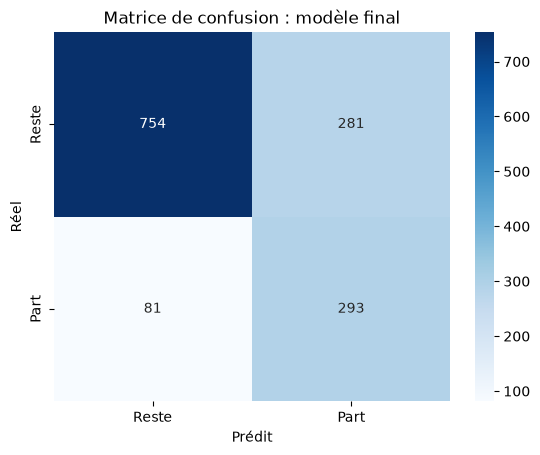

In [26]:
meilleur = grid.best_estimator_
pred_final = meilleur.predict(X_test)

print("=== Modèle final ===")
print(classification_report(y_test, pred_final, target_names=['Reste', 'Part']))

cm = confusion_matrix(y_test, pred_final)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Reste', 'Part'], yticklabels=['Reste', 'Part'])
plt.title("Matrice de confusion : modèle final")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.show()

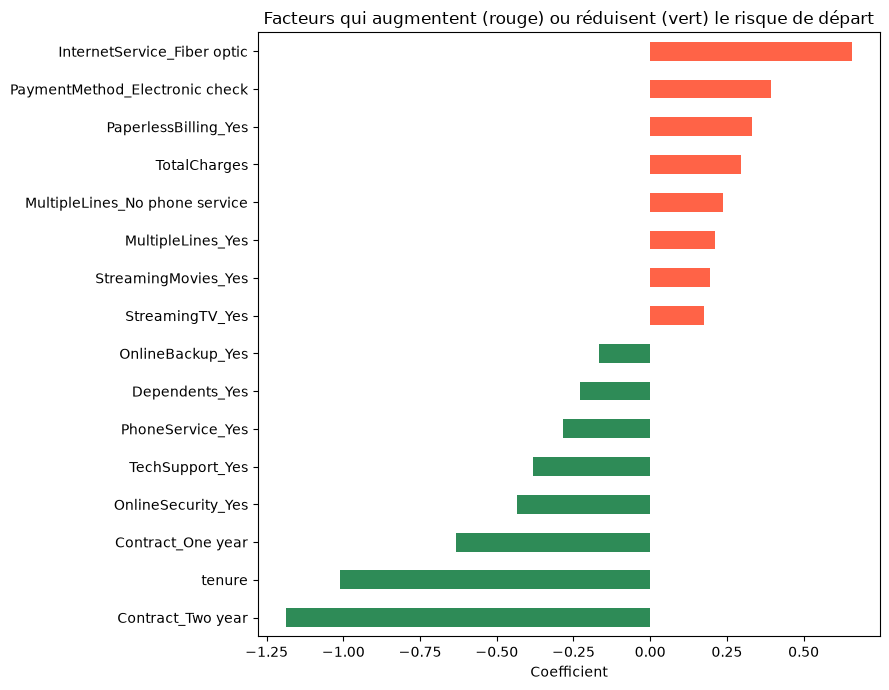

In [27]:
coefs = pd.Series(meilleur.coef_[0], index=X_train.columns).sort_values()

top = pd.concat([coefs.head(8), coefs.tail(8)])

plt.figure(figsize=(9, 7))
top.plot(kind='barh', color=['seagreen' if v < 0 else 'tomato' for v in top])
plt.title("Facteurs qui augmentent (rouge) ou réduisent (vert) le risque de départ")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

In [28]:
import joblib
joblib.dump(meilleur, 'modele_churn.pkl')
print("Modèle sauvegardé ✅")

Modèle sauvegardé ✅


In [29]:
print("=" * 50)
print("RÉSUMÉ DU PROJET : PRÉDICTION DU CHURN")
print("=" * 50)
print(f"Clients analysés        : {len(df)}")
print(f"Taux de churn           : {df['Churn'].mean() * 100:.1f}%")
print(f"Rappel (classe Part)    : {recall_score(y_test, pred_final) * 100:.1f}%")
print(f"Précision (classe Part) : {precision_score(y_test, pred_final) * 100:.1f}%")
print(f"F1-score                : {f1_score(y_test, pred_final) * 100:.1f}%")

RÉSUMÉ DU PROJET : PRÉDICTION DU CHURN
Clients analysés        : 7043
Taux de churn           : 26.5%
Rappel (classe Part)    : 78.3%
Précision (classe Part) : 51.0%
F1-score                : 61.8%
